## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Step 2: Load Dataset

In [2]:
df = pd.read_csv("Housing.csv")

df.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## Step 3: Understand the Dataset

In [3]:
df.shape

(545, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [5]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [6]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

## Step 4: Data Quality Report

In [7]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal duplicate rows:")
print(df.duplicated().sum())

print("\nColumn data types:")
print(df.dtypes)

Missing values in each column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Total duplicate rows:
0

Column data types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


## Step 5: Make a Copy

In [8]:
df_clean = df.copy()

## Step 6: Handle Missing Values

In [9]:
# Fill missing values in numerical columns with median

df_clean["price"] = df_clean["price"].fillna(df_clean["price"].median())
df_clean["area"] = df_clean["area"].fillna(df_clean["area"].median())
df_clean["bedrooms"] = df_clean["bedrooms"].fillna(df_clean["bedrooms"].median())
df_clean["bathrooms"] = df_clean["bathrooms"].fillna(df_clean["bathrooms"].median())
df_clean["stories"] = df_clean["stories"].fillna(df_clean["stories"].median())
df_clean["parking"] = df_clean["parking"].fillna(df_clean["parking"].median())

# Fill missing text values with mode

df_clean["mainroad"] = df_clean["mainroad"].fillna(df_clean["mainroad"].mode()[0])
df_clean["guestroom"] = df_clean["guestroom"].fillna(df_clean["guestroom"].mode()[0])
df_clean["basement"] = df_clean["basement"].fillna(df_clean["basement"].mode()[0])
df_clean["hotwaterheating"] = df_clean["hotwaterheating"].fillna(df_clean["hotwaterheating"].mode()[0])
df_clean["airconditioning"] = df_clean["airconditioning"].fillna(df_clean["airconditioning"].mode()[0])
df_clean["prefarea"] = df_clean["prefarea"].fillna(df_clean["prefarea"].mode()[0])
df_clean["furnishingstatus"] = df_clean["furnishingstatus"].fillna(df_clean["furnishingstatus"].mode()[0])

print(df_clean.isnull().sum())


price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


## Step 7: Remove Duplicate Rows

In [10]:
print("Duplicates before cleaning:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates after cleaning:", df_clean.duplicated().sum())


Duplicates before cleaning: 0
Duplicates after cleaning: 0


## Step 8: Standardise Text Values

In [11]:
df_clean["mainroad"] = df_clean["mainroad"].str.strip().str.lower()
df_clean["guestroom"] = df_clean["guestroom"].str.strip().str.lower()
df_clean["basement"] = df_clean["basement"].str.strip().str.lower()
df_clean["hotwaterheating"] = df_clean["hotwaterheating"].str.strip().str.lower()
df_clean["airconditioning"] = df_clean["airconditioning"].str.strip().str.lower()
df_clean["prefarea"] = df_clean["prefarea"].str.strip().str.lower()
df_clean["furnishingstatus"] = df_clean["furnishingstatus"].str.strip().str.lower()

print(df_clean.head())


      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


## Step 9: Find Outliers Using IQR

**Formula:**
- IQR = Q3 - Q1
- Lower limit = Q1 - 1.5 × IQR
- Upper limit = Q3 + 1.5 × IQR


In [12]:
# Find outliers in price

Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

price_outliers = df_clean[
    (df_clean["price"] < lower_limit) |
    (df_clean["price"] > upper_limit)
]

print("Price outliers:", len(price_outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


Price outliers: 15
Lower limit: -35000.0
Upper limit: 9205000.0


In [13]:
# Find outliers in area

Q1 = df_clean["area"].quantile(0.25)
Q3 = df_clean["area"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

area_outliers = df_clean[
    (df_clean["area"] < lower_limit) |
    (df_clean["area"] > upper_limit)
]

print("Area outliers:", len(area_outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


Area outliers: 12
Lower limit: -540.0
Upper limit: 10500.0


### Outlier decision

In [14]:
# No outliers are deleted in this project.
print("Outliers are identified and retained.")


Outliers are identified and retained.


### Box Plot: Visualise Outliers

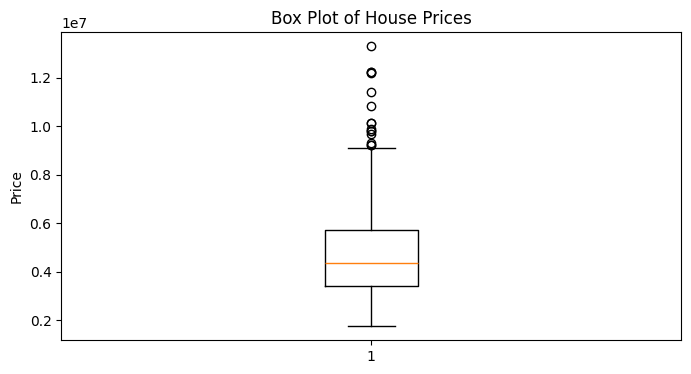

In [15]:
# Box plot for house price

plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["price"])
plt.title("Box Plot of House Prices")
plt.ylabel("Price")
plt.show()


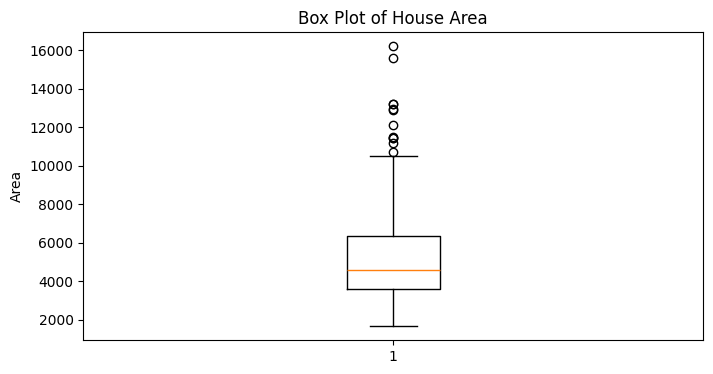

In [16]:
# Box plot for house area

plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["area"])
plt.title("Box Plot of House Area")
plt.ylabel("Area")
plt.show()


## Step 10: Correct Data Types

In [17]:
df_clean["price"] = df_clean["price"].astype("int64")
df_clean["area"] = df_clean["area"].astype("int64")
df_clean["bedrooms"] = df_clean["bedrooms"].astype("int64")
df_clean["bathrooms"] = df_clean["bathrooms"].astype("int64")
df_clean["stories"] = df_clean["stories"].astype("int64")
df_clean["parking"] = df_clean["parking"].astype("int64")

print(df_clean.dtypes)


price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


## Step 11: Before and After Comparison

In [18]:
print("BEFORE CLEANING")
print("Rows:", df.shape[0])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAFTER CLEANING")
print("Rows:", df_clean.shape[0])
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nData types after cleaning:")
print(df_clean.dtypes)


BEFORE CLEANING
Rows: 545
Missing values: 0
Duplicate rows: 0

AFTER CLEANING
Rows: 545
Missing values: 0
Duplicate rows: 0

Data types after cleaning:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


In [19]:
# Create a simple comparison table

comparison = pd.DataFrame({
    "Before Cleaning": [
        df.shape[0],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],
    "After Cleaning": [
        df_clean.shape[0],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
}, index=["Total Rows", "Missing Values", "Duplicate Rows"])

comparison


,Before Cleaning,After Cleaning
Total Rows,545,545
Missing Values,0,0
Duplicate Rows,0,0


## Step 12: Save Cleaned Dataset

In [23]:
df_clean.to_csv("Housing_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [24]:
Check the saved CSV file

new_df = pd.read_csv("Housing_Cleaned.csv")

print("Saved dataset shape:", new_df.shape)
new_df.head()


SyntaxError: invalid syntax (3718642216.py, line 1)

## Step 13: Conclusion

In this project, I cleaned the Housing dataset using beginner-level Python and Pandas operations. I checked missing values, duplicate rows, text formatting, outliers and data types. I documented the decisions taken at each step and saved the final dataset as `Housing_Cleaned.csv`.

The cleaned dataset can now be used for Exploratory Data Analysis (EDA) and House Price Prediction.

### Project files
- `Housing.csv` — original dataset
- `Housing_Data_Cleaning_Project.ipynb` — this notebook
- `Housing_Cleaned.csv` — output created after running the notebook
